<a href="https://colab.research.google.com/github/lilianam37/deep-minds/blob/main/notebooks/04_mlp_experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [14]:
#Grabing the cleaned train/val/test data found in preprocessing data
import pandas as pd
path = '/content/drive/MyDrive/DeepMinds/'

X_train = pd.read_csv(path+'X_train.csv'); y_train = pd.read_csv(path+'y_train.csv').squeeze()
X_val   = pd.read_csv(path+'X_val.csv');   y_val   = pd.read_csv(path+'y_val.csv').squeeze()
X_test  = pd.read_csv(path+'X_test.csv');  y_test  = pd.read_csv(path+'y_test.csv').squeeze()

print(X_train.shape, X_val.shape, X_test.shape)

(165056, 50) (35369, 50) (35370, 50)


In [15]:
#Shared grading function so every model gets scored the same way
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def evaluate(name, y_true, y_pred, y_prob):
    results = {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }
    print(results)
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=['Legit', 'Phishing'])
    plt.title(name); plt.show()
    return results

In [16]:
#Building an MLP of any size, then make a 64 → 32 one to start
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(42)

def build_mlp(hidden_layers):
    model = keras.Sequential([keras.Input(shape=(X_train.shape[1],))])
    for units in hidden_layers:
        model.add(keras.layers.Dense(units, activation='relu'))
    model.add(keras.layers.Dense(1, activation='sigmoid'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_mlp([64, 32])
model.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

In [17]:
#Training for 20 epochs, checking validation as we go
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=20, batch_size=256)

Epoch 1/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9937 - loss: 0.0266 - val_accuracy: 0.9997 - val_loss: 0.0011
Epoch 2/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9998 - loss: 7.6788e-04 - val_accuracy: 0.9999 - val_loss: 4.5724e-04
Epoch 3/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9999 - loss: 3.8936e-04 - val_accuracy: 0.9999 - val_loss: 2.9803e-04
Epoch 4/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9999 - loss: 2.8128e-04 - val_accuracy: 0.9999 - val_loss: 2.4343e-04
Epoch 5/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9999 - loss: 2.3222e-04 - val_accuracy: 0.9999 - val_loss: 2.1562e-04
Epoch 6/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9999 - loss: 2.0778e-04 - val_accuracy: 0.9999 - val_loss: 2.1579e-04
Epoch 7/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 1.0000 - loss: 1.8037e-04 - val_accuracy: 0.9999 - val_loss: 2.0460e-04
Epoch 8/20
645/645 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - ac

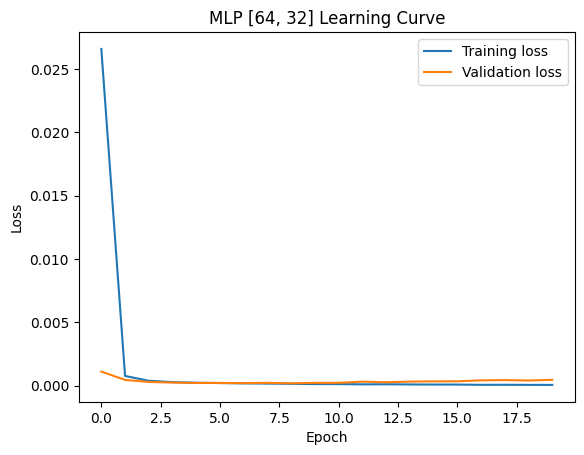

In [18]:
# Now we are plotting the learning curve to check for overfitting (and save it for the 3 page checkin/report thing)
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('MLP [64, 32] Learning Curve')
plt.legend()
plt.savefig(path+'mlp_loss_curve.png', dpi=200)
plt.show()

1106/1106 ━━━━━━━━━━━━━━━━━━━━ 1s 769us/step
{'Model': 'MLP [64, 32]', 'Accuracy': 0.9998869098105739, 'Precision': 1.0, 'Recall': 0.9997358341038172, 'F1': 0.9998678996036988, 'ROC-AUC': np.float64(0.9999992131700985)}


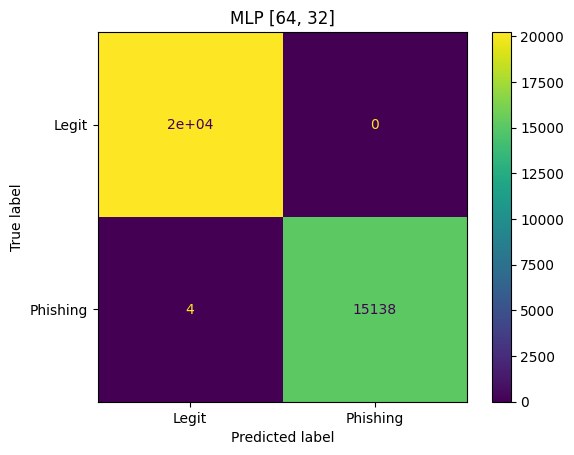

In [19]:
#Scoring the model on the test set (0.5+ probability = phishing) (below that = not)
probs = model.predict(X_test).ravel()
preds = (probs >= 0.5).astype(int)
mlp_results = evaluate('MLP [64, 32]', y_test, preds, probs)

{'Model': 'MLP [32]', 'Accuracy': 0.9999151823579304, 'Precision': 1.0, 'Recall': 0.9998018755778629, 'F1': 0.9999009279746376, 'ROC-AUC': np.float64(0.9999999608217476)}


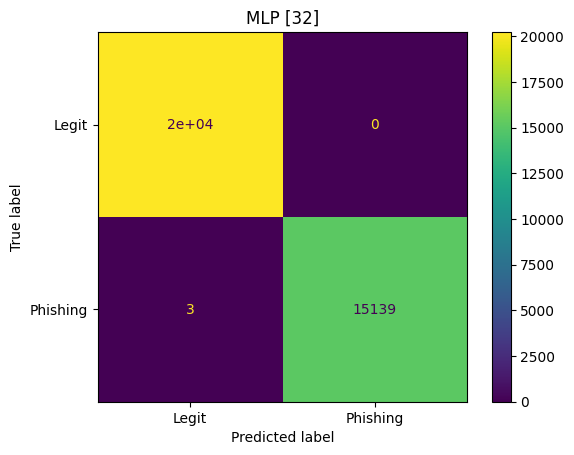

{'Model': 'MLP [64, 32]', 'Accuracy': 0.9998869098105739, 'Precision': 1.0, 'Recall': 0.9997358341038172, 'F1': 0.9998678996036988, 'ROC-AUC': np.float64(0.9999992131700985)}


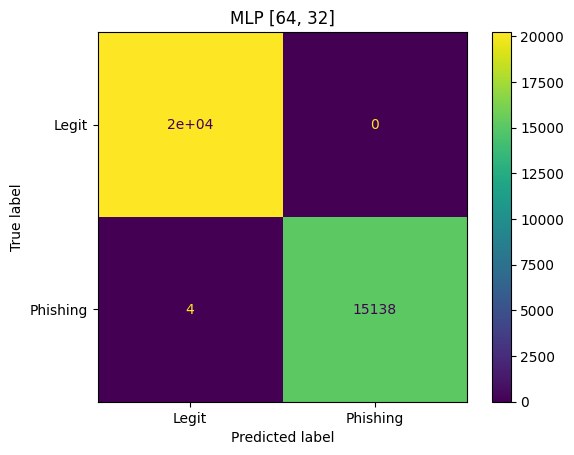

{'Model': 'MLP [128, 64, 32]', 'Accuracy': 0.9998869098105739, 'Precision': 1.0, 'Recall': 0.9997358341038172, 'F1': 0.9998678996036988, 'ROC-AUC': np.float64(0.9999940547002057)}


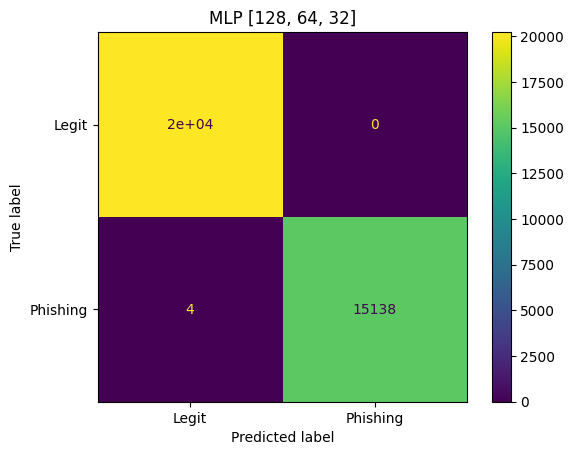

In [20]:
#Train three MLP sizes with identical settings and score each one on the test set
sizes = [[32], [64, 32], [128, 64, 32]]
mlp_results, histories = [], {}

for layers in sizes:
    tf.keras.utils.set_random_seed(42)
    m = build_mlp(layers)
    h = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=256, verbose=0)
    histories[str(layers)] = h
    probs = m.predict(X_test, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    res = evaluate(f'MLP {layers}', y_test, preds, probs)
    res['Params'] = m.count_params()
    mlp_results.append(res)

In [21]:
#Put all three results in one table and save it for the report
results_table = pd.DataFrame(mlp_results).round(4)
display(results_table)
results_table.to_csv(path+'mlp_experiment_results.csv', index=False)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Params
0,MLP [32],0.9999,1.0,0.9998,0.9999,1.0,1665
1,"MLP [64, 32]",0.9999,1.0,0.9997,0.9999,1.0,5377
2,"MLP [128, 64, 32]",0.9999,1.0,0.9997,0.9999,1.0,16897


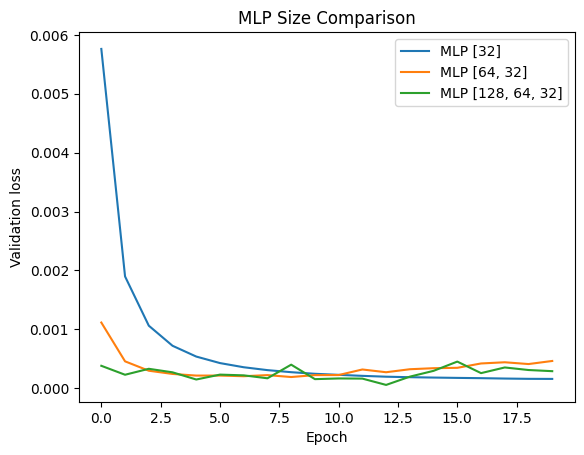

In [22]:
#Compare validation loss for all three sizes on one graph
for name, h in histories.items():
    plt.plot(h.history['val_loss'], label=f'MLP {name}')
plt.xlabel('Epoch'); plt.ylabel('Validation loss'); plt.title('MLP Size Comparison')
plt.legend()
plt.savefig(path+'mlp_size_comparison.png', dpi=200)
plt.show()

In [23]:
#Rerun the size experiment on the validation set and count actual mistakes
from sklearn.metrics import confusion_matrix
val_rows = []
for layers in [[32], [64, 32], [128, 64, 32]]:
    tf.keras.utils.set_random_seed(42)
    m = build_mlp(layers)
    m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=256, verbose=0)
    probs = m.predict(X_val, verbose=0).ravel()
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()
    val_rows.append({'Model': f'MLP {layers}', 'Accuracy': accuracy_score(y_val, preds),
                     'Precision': precision_score(y_val, preds), 'Recall': recall_score(y_val, preds),
                     'Missed': fn, 'False alarms': fp, 'Params': m.count_params()})
val_table = pd.DataFrame(val_rows)
print(val_table.round(4).to_string(index=False))
val_table.to_csv(path+'mlp_experiment_validation.csv', index=False)

            Model  Accuracy  Precision  Recall  Missed  False alarms  Params
         MLP [32]    0.9999        1.0  0.9999       2             0    1665
     MLP [64, 32]    0.9999        1.0  0.9998       3             0    5377
MLP [128, 64, 32]    0.9999        1.0  0.9998       3             0   16897


Observations on MLP: All three neural network sizes did almost perfectly at spotting the various phishing websites, correctly classifying 99.99% of the test sites. None of them ever falsely flagged a real website as phishing, and each missed only a few actual phishing sites. Making the network bigger didn’t actually make it any better, so the smaller network was just as good. This likely happened because one of the dataset’s features, URLSimilarityIndex (how closely a URL resembles known legitimate ones), already gives away most of the answer, leaving little room for a more complex model to improve.